# **Exploration et Analyse de la Qualité des Données (EDA)**

In [111]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pypalettes import load_cmap
import numpy as np

In [112]:
palette = ["#025940FF","#04AC6EFF","#03A62CFF" , "#038C33FF", "#0F1926FF"]

In [113]:
#Lien API:ce lien va nous servir a récupérer la base de donné sans besoin de la télécharger en local.
url = "https://www.data.gouv.fr/fr/datasets/r/a27a4212-6732-408e-85e4-819ce897046b"

df = pd.read_csv(url, sep=";", low_memory=False)

print(df.info())
print(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 19603 entries, 0 to 19602
Data columns (total 35 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   annee                                          19603 non-null  int64  
 1   diplome                                        19603 non-null  str    
 2   numero_de_l_etablissement                      19603 non-null  str    
 3   etablissement                                  19603 non-null  str    
 4   etablissementactuel                            4454 non-null   str    
 5   code_de_l_academie                             19242 non-null  str    
 6   academie                                       19242 non-null  str    
 7   code_du_domaine                                19603 non-null  str    
 8   domaine                                        19603 non-null  str    
 9   code_de_la_discipline                          19603 non-null

In [114]:
# cols_a_supprimer ce sont les colonnes qu'on a éffacer car on ne les trouves pas intéresant.
cols_a_supprimer =[
    "numero_de_l_etablissement",
    "cle_etab",
    "cle_disc",
    "id_paysage",
    "etablissementactuel",
    "remarque",
    "code_de_l_academie",
    "code_du_domaine",
    "code_de_la_discipline",
]
# cols_numeriques ce sont les colonnes qu'on doit convertir en numerique, car ils était en "str"
cols_numeriques = [
    "taux_de_reponse",
    "poids_de_la_discipline",
    "taux_dinsertion",
    "taux_d_emploi",
    "taux_d_emploi_salarie_en_france",
    "emplois_cadre_ou_professions_intermediaires",
    "emplois_stables",
    "emplois_a_temps_plein",
    "salaire_net_median_des_emplois_a_temps_plein",
    "salaire_brut_annuel_estime",
    "de_diplomes_boursiers",
    "taux_de_chomage_regional",
    "salaire_net_mensuel_median_regional",
    "emplois_cadre",
    "emplois_exterieurs_a_la_region_de_luniversite",
    "femmes",
    "salaire_net_mensuel_regional_1er_quartile",
    "salaire_net_mensuel_regional_3eme_quartile",
    "nombre_de_reponses",
]


In [115]:
# éffacer les colonnes non nécessaire
df = df.drop(columns=cols_a_supprimer, errors="ignore")

# conversion des colonne à numérique
for col in cols_numeriques:
    df[col] = (
        df[col]
        .astype(str)
        .str.replace(",", ".")
        .str.replace("%", "")
        .str.strip()
    )
    df[col] = pd.to_numeric(df[col], errors="coerce")



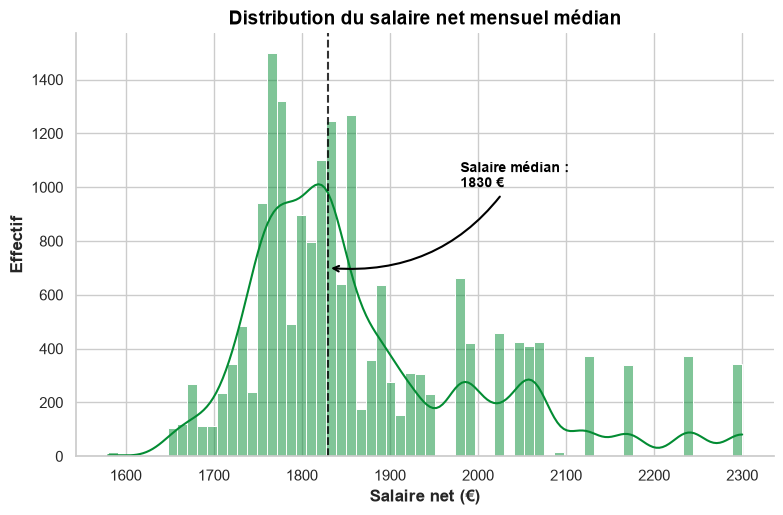

In [116]:

mediane_salaire = df["salaire_net_mensuel_median_regional"].median()

plt.figure(figsize=(9, 5.5))

ax = sns.histplot(
    df["salaire_net_mensuel_median_regional"].dropna(),
    kde=True,
    color="#038C33FF", 
)

plt.axvline(
    x=mediane_salaire, color="#000000", linestyle="--", linewidth=1.5, alpha=0.8
)

ax.annotate(
    text=f"Salaire médian :\n{mediane_salaire:.0f} €",
    xy=(mediane_salaire, 700),
    xytext=(
        mediane_salaire + 150,
        1000,
    ),  
    arrowprops=dict(
        arrowstyle="->",
        connectionstyle="arc3,rad=-0.3", 
        color="#000000",
        lw=1.5,
    ),
    fontsize=10,
    fontweight="bold",
    color="#000000",
    ha="left",
)


plt.title(
    "Distribution du salaire net mensuel médian", fontsize=14, fontweight="bold", color="#000000"
)
plt.xlabel("Salaire net (€)", fontweight="bold")
plt.ylabel("Effectif", fontweight="bold")
sns.despine()

plt.show()


**Commentaire analytique  :**

La distribution du salaire net mensuel médian présente une asymétrie à droite (*right-skewed*) ainsi qu'une structure multimodale. Le pic principal se concentre entre **1 750 € et 1 850 €**, représentant le cœur des rémunérations médianes pour la majorité des diplômés. On observe ensuite des modes secondaires étalés entre **2 000 € et 2 300 €**, reflétant des disparités de salaires selon les domaines d'études ou les régions.

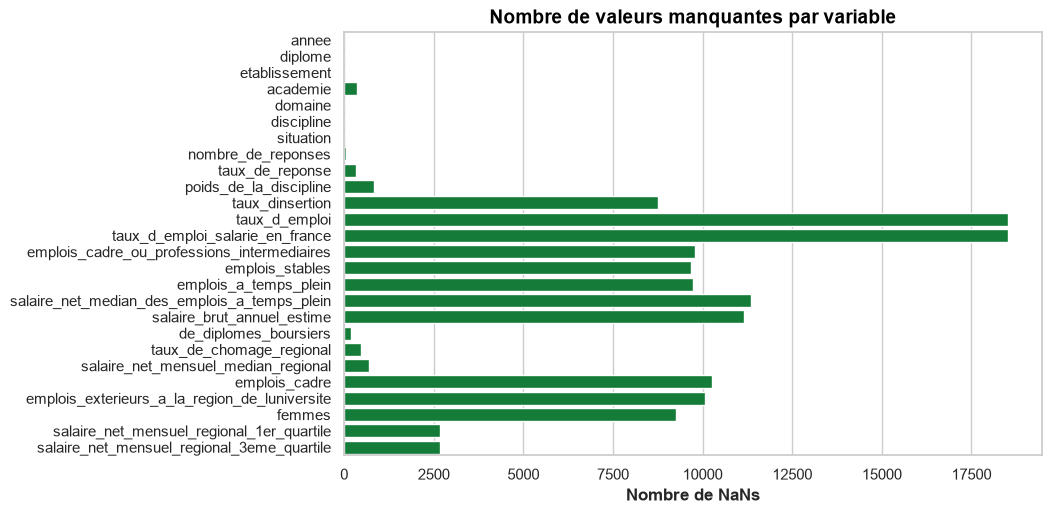

In [117]:
plt.figure(figsize=(9, 5.5))
sns.barplot(x=df.isnull().sum(), y=df.columns, color="#038C33FF")
plt.title("Nombre de valeurs manquantes par variable", fontsize=14, fontweight="bold", color="#000000")
plt.xlabel("Nombre de NaNs", fontweight="bold")
plt.ylabel("")
plt.show()


**Commentaire analytique :**

L'analyse du profil des données manquantes révèle une forte disparité selon la nature des variables du jeu de données. D'un côté, les variables qualitatives de cadrage administratif et descriptif (`annee`, `diplome`, `etablissement`, `domaine`, `discipline`, `situation`) présentent une complétude quasi parfaite avec aucun NaN recensé. De l'autre côté, deux sous-groupes d'indicateurs quantitatifs concentrent l'essentiel de l'incomplétude : d'une part, les variables relatives au marché de l'emploi (`taux_d_emploi`, `taux_d_emploi_salarie_en_france`, `emplois_stables`, `emplois_a_temps_plein`, `emplois_cadre`) qui dépassent les 10 000 ou 18 000 données manquantes sur les 19 603 observations, et d'autre part, les métriques salariales précises (`salaire_net_median_des_emplois_a_temps_plein`, `salaire_brut_annuel_estime`).
Ce niveau élevé de données manquantes sur certains indicateurs clés de l'insertion découle du secret statistique (effectifs de répondants trop faibles par diplôme ou université) et impose des arbitrages stricts lors de la phase de prétraitement.

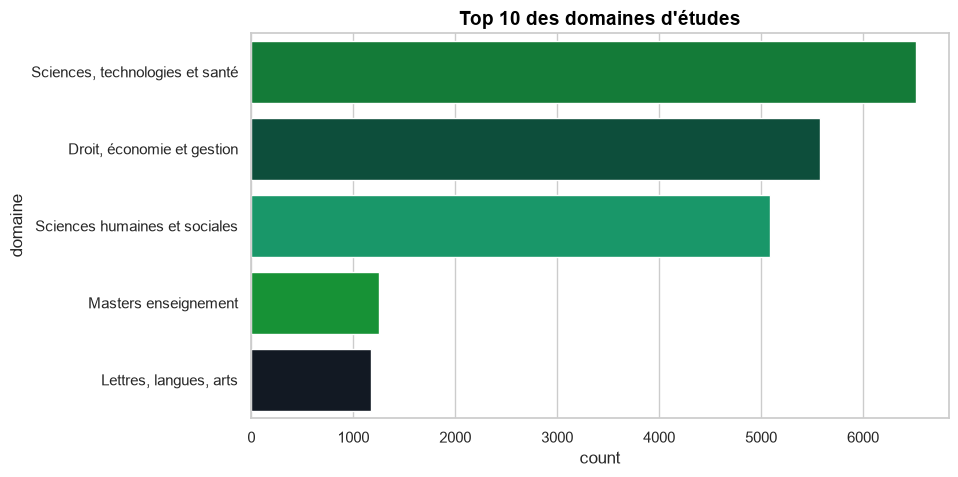

In [118]:
plt.figure(figsize=(9, 5))

sns.countplot(
    y="domaine",
    data=df,
    order=df["domaine"].value_counts().index[:10],
    palette=palette,
    hue="domaine",  
    legend=False,
)

plt.title("Top 10 des domaines d'études", fontsize=14, fontweight="bold", color="#000000")
plt.show()

**Commentaire analytique :**

L'analyse de la structure du jeu de données par grand domaine académique met en évidence une très forte concentration des effectifs autour de trois filières principales. Le secteur **« Sciences, technologies et santé »** prédomine nettement avec plus de 6 500 observations, suivi de près par **« Droit, économie et gestion »** (~5 600) et **« Sciences humaines et sociales »** (~5 100). À l'opposé, les **« Masters enseignement »** et les filières **« Lettres, langues, arts »** sont nettement moins représentés, comptabilisant chacun un peu plus de 1 000 individus.
Cette nette disparité d'effectifs reflète un déséquilibre structurel entre les sous-échantillons disciplinaires.

c:\Users\kenny\Documents\Master Mécen 2025-2027\M2\Webscraping\Projet_ML\.venv\Lib\site-packages\seaborn\categorical.py:700: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  artists = ax.bxp(**boxplot_kws)


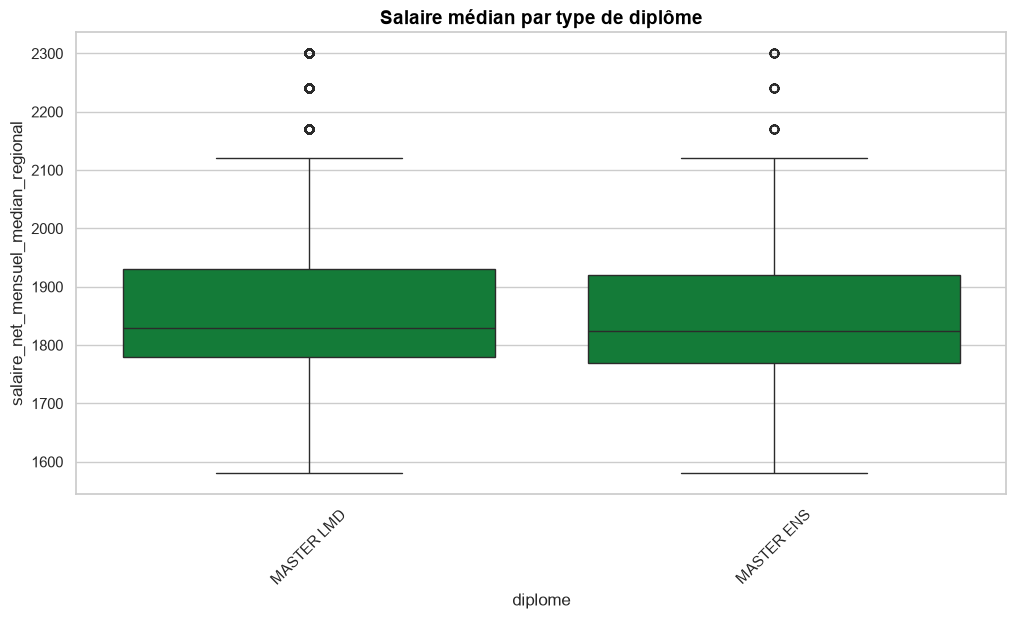

In [119]:
plt.figure(figsize=(12, 6))
sns.boxplot(
    x="diplome", y="salaire_net_mensuel_median_regional", data=df, color="#038C33FF"
)
plt.title("Salaire médian par type de diplôme", fontsize=14, fontweight="bold", color="#000000")
plt.xticks(rotation=45)
plt.show()

**Commentaire analytique :**

 L'analyse de la distribution des rémunérations selon la typologie du diplôme (`diplome`) ne révèle aucune différence significative entre les deux parcours universitaires recensés dans le jeu de données. Pour le **Master LMD** (parcours classique de Master généraliste ou spécialisé au sein du schéma européen Licence-Master-Doctorat) comme pour le **Master ENS** (Master Métiers de l'Enseignement, de l'Éducation et de la Formation/ MEEF / Enseignement), le salaire net mensuel médian s'établit autour d'un niveau équivalent d'environ **1 825 € à 1 830 €**.
Les deux distributions présentent un écart interquartile quasiment identique (compris entre ~1 780 € et ~1 930 €), ainsi que des valeurs extrêmes identiques atteignant jusqu'à 2 300 €. Cette grande homogénéité indique que la nature du diplôme de niveau bac+5 (Master LMD vs Master MEEF/Enseignement) ne constitue pas un facteur discriminant pour la prédiction de la rémunération. En conséquence, la variable `diplome` offrira un pouvoir prédictif très faible pour nos modèles de régression et pourra faire l'objet d'un filtrage ou d'un regroupement lors du *feature engineering*.

In [ ]:
# Comptage des lignes strictement identiquement doublées
nb_doublons = df.duplicated().sum()
print(f"Nombre de lignes parfaitement doublées : {nb_doublons}")


Nombre de lignes parfaitement doublées : 0


In [123]:
print("APERÇU DE COHÉRENCE DES VARIABLES CLÉS ")
if "salaire_net_mensuel_median_regional" in df.columns:
    salaires = df["salaire_net_mensuel_median_regional"].dropna()
    q1, q3 = np.percentile(salaires, [25, 75])
    iqr = q3 - q1
    lower_bound = q1 - (1.5 * iqr)
    upper_bound = q3 + (1.5 * iqr)
    outliers = salaires[(salaires < lower_bound) | (salaires > upper_bound)]
    print(
        f"Nombre potentiel d'outliers pour le salaire (avec la méthode IQR) : {len(outliers)}"
    )

APERÇU DE COHÉRENCE DES VARIABLES CLÉS 
Nombre potentiel d'outliers pour le salaire (avec la méthode IQR) : 1056


 **Diagnostic de la qualité des données**
L'évaluation initiale du jeu de données révèle l'absence de doublons stricts au niveau des observations. L'analyse des valeurs manquantes met en lumière une division claire de la base : les données descriptives administratives sont complètes à 100 %, tandis que les indicateurs relatifs à la rémunération et au type d'emploi présentent un taux d'incomplétude élevé (supérieur à 45 % sur certaines variables), lié au secret statistique imposé par le Ministère lorsque les cohortes d'étudiants sont restreintes.
 